In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:

url = "https://huggingface.co/datasets/PatZhang0214/business-risk-prediction-dataset/resolve/main/v3/yelp_fred_merged.parquet"

df = pd.read_parquet(url)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Rows and columns: (16822, 66)


,business_id,rating_x_reviews,review_count,num_categories,years_in_business,num_checkins,has_checkin,is_open,latitude,longitude,...,cat_Hotels,cat_Chinese,cat_Desserts,cat_Chicken Wings,cat_Cafes,cat_Caterers,cat_Ice Cream & Frozen Yogurt,cat_Venues & Event Spaces,cat_Pet Services,cat_Tires
0,Pns2l4eNsfO8kk83dixA6A,10.397208,7,6,0.000000,1,1,0,34.426679,-119.711197,...,0,0,0,0,0,0,0,0,0,0
1,mpf3x-BjTdTEA3yCZrAYPw,8.317766,15,5,8.999316,15,1,1,38.551126,-90.335695,...,0,0,0,0,0,0,0,0,0,0
2,tUFrWirKiKi_TAnsVWINQQ,10.974230,22,6,8.785763,401,1,0,32.223236,-110.880452,...,0,0,0,0,0,0,0,0,0,0
3,MTSW4McQd7CbVtyjqoe9mw,17.577797,80,5,11.277207,335,1,1,39.955505,-75.155564,...,0,0,0,0,0,0,0,0,0,0
4,mWMc6_wTdE0EUBKIGXDVfA,11.875758,13,3,2.472279,14,1,1,40.338183,-75.471659,...,0,0,0,0,0,0,0,0,0,0


In [3]:

print("Dataset shape:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe().T)


Dataset shape:
(16822, 66)

Column names:
['business_id', 'rating_x_reviews', 'review_count', 'num_categories', 'years_in_business', 'num_checkins', 'has_checkin', 'is_open', 'latitude', 'longitude', 'fips', 'pcpi', 'poverty_rate', 'median_household_income', 'unemployment_rate', 'avg_weekly_wages', 'cat_Restaurants', 'cat_Food', 'cat_Shopping', 'cat_Home Services', 'cat_Beauty & Spas', 'cat_Health & Medical', 'cat_Nightlife', 'cat_Local Services', 'cat_Automotive', 'cat_Bars', 'cat_Event Planning & Services', 'cat_Sandwiches', 'cat_Active Life', 'cat_American (Traditional)', 'cat_Pizza', 'cat_Fast Food', 'cat_Coffee & Tea', 'cat_Breakfast & Brunch', 'cat_American (New)', 'cat_Hotels & Travel', 'cat_Home & Garden', 'cat_Fashion', 'cat_Arts & Entertainment', 'cat_Burgers', 'cat_Auto Repair', 'cat_Hair Salons', 'cat_Italian', 'cat_Mexican', 'cat_Nail Salons', 'cat_Specialty Food', 'cat_Pets', 'cat_Doctors', 'cat_Real Estate', 'cat_Seafood', 'cat_Fitness & Instruction', 'cat_Professional S

,count,mean,std,min,25%,50%,75%,max
rating_x_reviews,16822.0,11.065465,5.091766,1.791759,7.361097,9.996614,13.862944,34.498616
review_count,16822.0,46.732315,116.022501,5.000000,8.000000,15.000000,39.000000,4554.000000
num_categories,16822.0,4.454702,2.238911,1.000000,3.000000,4.000000,6.000000,23.000000
years_in_business,16822.0,4.775114,3.925665,0.000000,0.807666,4.350445,8.227242,12.002738
num_checkins,16822.0,92.400071,306.036446,0.000000,3.000000,14.000000,62.000000,10063.000000
...,...,...,...,...,...,...,...,...
cat_Caterers,16822.0,0.018844,0.135979,0.000000,0.000000,0.000000,0.000000,1.000000
cat_Ice Cream & Frozen Yogurt,16822.0,0.018369,0.134285,0.000000,0.000000,0.000000,0.000000,1.000000
cat_Venues & Event Spaces,16822.0,0.018131,0.133429,0.000000,0.000000,0.000000,0.000000,1.000000
cat_Pet Services,16822.0,0.018428,0.134498,0.000000,0.000000,0.000000,0.000000,1.000000


is_open
1    13416
0     3406
Name: count, dtype: int64
is_open
1    79.752705
0    20.247295
Name: proportion, dtype: float64


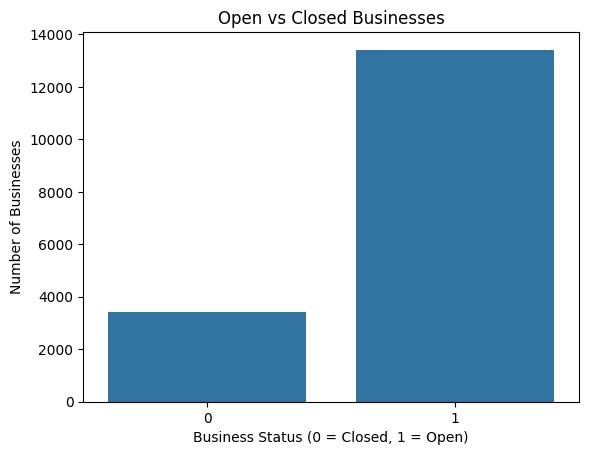

In [4]:

print(df["is_open"].value_counts())

print(
    df["is_open"].value_counts(normalize=True) * 100
)

sns.countplot(data=df, x="is_open")

plt.title("Open vs Closed Businesses")
plt.xlabel("Business Status (0 = Closed, 1 = Open)")
plt.ylabel("Number of Businesses")
plt.show()


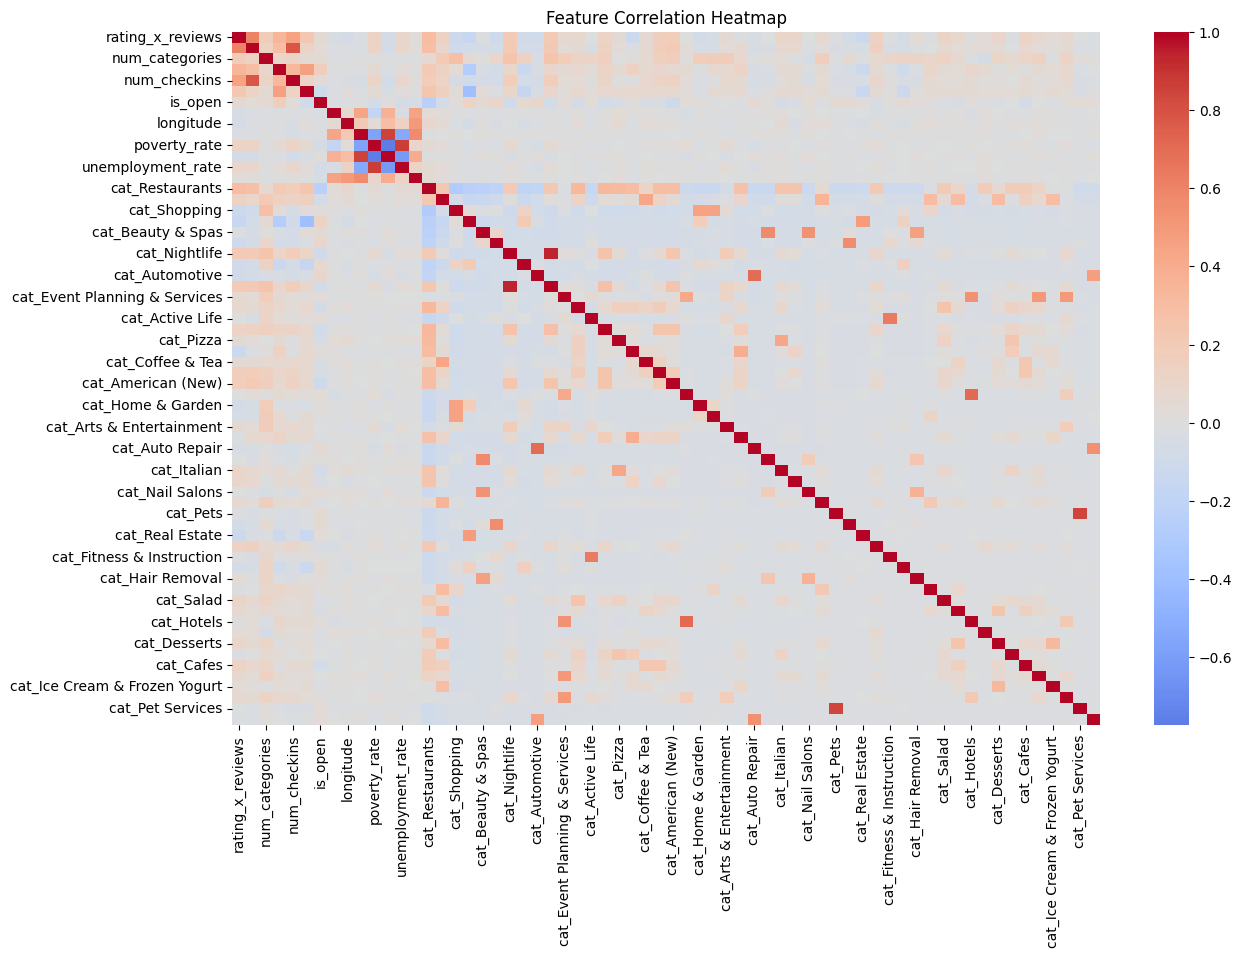

In [5]:

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(14, 9))

sns.heatmap(
    numeric_df.corr(),
    cmap="coolwarm",
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.show()


In [6]:

target = "is_open"

df = df.drop_duplicates().copy()

df[target] = pd.to_numeric(df[target], errors="coerce")

df = df.dropna(subset=[target])

df = df[df[target].isin([0, 1])].copy()

df[target] = df[target].astype(int)

# Remove identifiers and direct target
excluded = [
    "is_open",
    "business_id",
    "name",
    "address",
    "fips"
]

features = [
    col for col in df.columns
    if col not in excluded
    and (
        pd.api.types.is_numeric_dtype(df[col])
        or col.startswith("cat_")
    )
]

X = df[features].copy()
y = df[target].copy()

print("Selected features:", len(features))
print("Feature matrix:", X.shape)
print("Target distribution:")
print(y.value_counts())


Selected features: 63
Feature matrix: (16822, 63)
Target distribution:
is_open
1    13416
0     3406
Name: count, dtype: int64


In [7]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])


Training samples: 13457
Testing samples: 3365


In [8]:

numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])


In [9]:

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=15,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    )
}


In [10]:

trained_models = {}
results = []

for name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    }

    results.append(metrics)
    trained_models[name] = pipeline

    print(name, "training completed!")

results_df = pd.DataFrame(results)

display(
    results_df.sort_values("F1 Score", ascending=False)
)


Logistic Regression training completed!
Random Forest training completed!
XGBoost training completed!


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,XGBoost,0.847845,0.871663,0.948957,0.908669,0.846044
1,Random Forest,0.787816,0.904351,0.820790,0.860547,0.826588
0,Logistic Regression,0.676374,0.897359,0.671013,0.767853,0.749653


Best model: XGBoost

Classification Report:
              precision    recall  f1-score   support

      Closed       0.69      0.45      0.54       681
        Open       0.87      0.95      0.91      2684

    accuracy                           0.85      3365
   macro avg       0.78      0.70      0.73      3365
weighted avg       0.84      0.85      0.83      3365



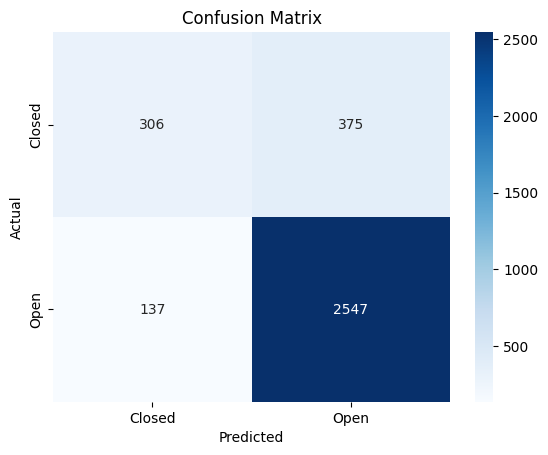

In [11]:

best_name = results_df.sort_values(
    "F1 Score",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_name]

print("Best model:", best_name)

y_pred = best_model.predict(X_test)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Closed", "Open"]
))

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Closed", "Open"],
    yticklabels=["Closed", "Open"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


In [12]:

import os
import json
import joblib

os.makedirs("shopsurvival_models", exist_ok=True)

joblib.dump(
    best_model,
    "shopsurvival_models/shopsurvival_model.pkl"
)

with open(
    "shopsurvival_models/features.json",
    "w"
) as f:
    json.dump(features, f)

print("Model saved:", best_name)


Model saved: XGBoost


In [13]:

from google.colab import files

files.download(
    "shopsurvival_models/shopsurvival_model.pkl"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:

files.download(
    "shopsurvival_models/features.json"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:

loaded_model = joblib.load(
    "shopsurvival_models/shopsurvival_model.pkl"
)

sample = X_test.iloc[[0]]

prediction = loaded_model.predict(sample)[0]

probability = loaded_model.predict_proba(sample)[0]

print("Predicted status:",
      "Open" if prediction == 1 else "Closed")

print("Closed probability:",
      round(probability[0] * 100, 2), "%")

print("Open probability:",
      round(probability[1] * 100, 2), "%")


Predicted status: Open
Closed probability: 14.47 %
Open probability: 85.53 %


In [17]:

from sklearn.metrics import classification_report

print("MODEL:", best_name)

print(classification_report(
    y_test,
    best_model.predict(X_test),
    target_names=["Closed", "Open"]
))

print("Model comparison:")
display(
    results_df.sort_values(
        "F1 Score",
        ascending=False
    )
)


MODEL: XGBoost
              precision    recall  f1-score   support

      Closed       0.69      0.45      0.54       681
        Open       0.87      0.95      0.91      2684

    accuracy                           0.85      3365
   macro avg       0.78      0.70      0.73      3365
weighted avg       0.84      0.85      0.83      3365

Model comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,XGBoost,0.847845,0.871663,0.948957,0.908669,0.846044
1,Random Forest,0.787816,0.904351,0.820790,0.860547,0.826588
0,Logistic Regression,0.676374,0.897359,0.671013,0.767853,0.749653


In [18]:

print("Open businesses:", (y_test == 1).sum())
print("Closed businesses:", (y_test == 0).sum())


Open businesses: 2684
Closed businesses: 681


In [19]:

from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_weight = negative / positive

print("Closed/Open weight:", scale_weight)

improved_xgb = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=3,
        scale_pos_weight=scale_weight,
        eval_metric="logloss",
        random_state=42
    ))
])

improved_xgb.fit(X_train, y_train)

print("Improved model trained!")


Closed/Open weight: 0.25391352963101005
Improved model trained!


In [20]:
import joblib
import os

model_path = "shopsurvival_models/shopsurvival_model.pkl"

model = joblib.load(model_path)

print("ShopSurvival Model Loaded Successfully!")
print("Model Type:", type(model).__name__)

ShopSurvival Model Loaded Successfully!
Model Type: Pipeline


In [21]:
print("Total Features:", len(features))

for feature in features:
    print(feature)

Total Features: 63
rating_x_reviews
review_count
num_categories
years_in_business
num_checkins
has_checkin
latitude
longitude
pcpi
poverty_rate
median_household_income
unemployment_rate
avg_weekly_wages
cat_Restaurants
cat_Food
cat_Shopping
cat_Home Services
cat_Beauty & Spas
cat_Health & Medical
cat_Nightlife
cat_Local Services
cat_Automotive
cat_Bars
cat_Event Planning & Services
cat_Sandwiches
cat_Active Life
cat_American (Traditional)
cat_Pizza
cat_Fast Food
cat_Coffee & Tea
cat_Breakfast & Brunch
cat_American (New)
cat_Hotels & Travel
cat_Home & Garden
cat_Fashion
cat_Arts & Entertainment
cat_Burgers
cat_Auto Repair
cat_Hair Salons
cat_Italian
cat_Mexican
cat_Nail Salons
cat_Specialty Food
cat_Pets
cat_Doctors
cat_Real Estate
cat_Seafood
cat_Fitness & Instruction
cat_Professional Services
cat_Hair Removal
cat_Grocery
cat_Salad
cat_Bakeries
cat_Hotels
cat_Chinese
cat_Desserts
cat_Chicken Wings
cat_Cafes
cat_Caterers
cat_Ice Cream & Frozen Yogurt
cat_Venues & Event Spaces
cat_Pet Se

In [22]:
import joblib
import pandas as pd

model = joblib.load(
    "shopsurvival_models/shopsurvival_model.pkl"
)

# Take one business record from test dataset
sample_business = X_test.iloc[[0]].copy()

# Predict business status
prediction = model.predict(sample_business)[0]

# Get probabilities
probabilities = model.predict_proba(sample_business)[0]

classes = list(model.classes_)

open_probability = probabilities[classes.index(1)] * 100
closed_probability = probabilities[classes.index(0)] * 100

predicted_status = "Open" if prediction == 1 else "Closed"

print("===== SHOP SURVIVAL PREDICTION =====")
print("Predicted Status:", predicted_status)
print(f"Open Probability: {open_probability:.2f}%")
print(f"Closed Probability: {closed_probability:.2f}%")

print("\n===== BUSINESS INPUT DETAILS =====")
display(sample_business)

===== SHOP SURVIVAL PREDICTION =====
Predicted Status: Open
Open Probability: 85.53%
Closed Probability: 14.47%

===== BUSINESS INPUT DETAILS =====


,rating_x_reviews,review_count,num_categories,years_in_business,num_checkins,has_checkin,latitude,longitude,pcpi,poverty_rate,...,cat_Hotels,cat_Chinese,cat_Desserts,cat_Chicken Wings,cat_Cafes,cat_Caterers,cat_Ice Cream & Frozen Yogurt,cat_Venues & Event Spaces,cat_Pet Services,cat_Tires
6006,7.083033,16,5,2.472279,4,1,39.950715,-75.144686,53304.0,24.3,...,0,0,0,0,0,0,0,0,0,0


In [23]:
actual_status = y_test.iloc[0]

print("Actual Status:",
      "Open" if actual_status == 1 else "Closed")

print("Predicted Status:", predicted_status)

if actual_status == prediction:
    print("Prediction: Correct")
else:
    print("Prediction: Incorrect")

Actual Status: Open
Predicted Status: Open
Prediction: Correct


In [24]:
def predict_business_status(input_data):

    input_df = pd.DataFrame([input_data])

    prediction = model.predict(input_df)[0]
    probabilities = model.predict_proba(input_df)[0]

    classes = list(model.classes_)

    open_probability = probabilities[classes.index(1)] * 100
    closed_probability = probabilities[classes.index(0)] * 100

    status = "Open" if prediction == 1 else "Closed"

    return {
        "Predicted Status": status,
        "Open Probability": round(open_probability, 2),
        "Closed Probability": round(closed_probability, 2)
    }

In [25]:
sample_input = X_test.iloc[0].to_dict()

result = predict_business_status(sample_input)

print("===== SHOP SURVIVAL RESULT =====")

for key, value in result.items():
    print(key, ":", value)

===== SHOP SURVIVAL RESULT =====
Predicted Status : Open
Open Probability : 85.53
Closed Probability : 14.47


In [26]:
import json

with open("shopsurvival_models/features.json", "w") as f:
    json.dump(features, f)

print("Feature list saved successfully!")
print("Total Features:", len(features))

Feature list saved successfully!
Total Features: 63


In [27]:
import shutil

shutil.make_archive(
    "shopsurvival_models",
    "zip",
    "shopsurvival_models"
)

from google.colab import files
files.download("shopsurvival_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [28]:
import joblib
import os

os.makedirs("shopsurvival_models", exist_ok=True)

# Extract preprocessing and XGBoost classifier
preprocessor = best_model.named_steps["preprocessing"]
xgb_model = best_model.named_steps["classifier"]

# Save preprocessing separately
joblib.dump(
    preprocessor,
    "shopsurvival_models/preprocessor.pkl"
)

# Save XGBoost in native JSON format
xgb_model.save_model(
    "shopsurvival_models/xgb_model.json"
)

# Save feature list
import json

with open("shopsurvival_models/features.json", "w") as f:
    json.dump(features, f)

print("Model files saved successfully!")

Model files saved successfully!


In [29]:
from google.colab import files

files.download("shopsurvival_models/preprocessor.pkl")
files.download("shopsurvival_models/xgb_model.json")
files.download("shopsurvival_models/features.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>